# AlertaEdu - Resultados
Notebook que carrega os artefatos gerados por `src.eda`, `src.train` e `src.explain`.
Para reproduzir: `python -m src.eda && python -m src.train && python -m src.explain`.

In [1]:
import sys; sys.path.insert(0, '..')
import pandas as pd
from IPython.display import Image, display
from src.data import load_data, make_binary_target
df = load_data(); y = make_binary_target(df)
print(df.shape, 'taxa de evas?o:', round(y.mean(), 3))
df['Target'].value_counts()

(4424, 37) taxa de evas?o: 0.321


Target
Graduate    2209
Dropout     1421
Enrolled     794
Name: count, dtype: int64

## Compara??o de modelos (teste)

In [2]:
m = pd.read_csv('../reports/metricas_modelos.csv')
m[['cenario','modelo','cv_f1','teste_precision','teste_recall','teste_f1','teste_roc_auc']].round(3)

,cenario,modelo,cv_f1,teste_precision,teste_recall,teste_f1,teste_roc_auc
0,A_matricula,Baseline (classe majoritária),0.000,0.000,0.000,0.000,0.500
1,A_matricula,Regressão Logística,0.646,0.601,0.715,0.653,0.838
2,A_matricula,Random Forest,0.623,0.710,0.602,0.651,0.825
3,A_matricula,XGBoost,0.639,0.629,0.697,0.661,0.835
4,B_1_semestre,Baseline (classe majoritária),0.000,0.000,0.000,0.000,0.500
5,B_1_semestre,Regressão Logística,0.761,0.762,0.810,0.785,0.914
6,B_1_semestre,Random Forest,0.756,0.805,0.739,0.771,0.908
7,B_1_semestre,XGBoost,0.763,0.773,0.803,0.788,0.911
8,C_2_semestre,Baseline (classe majoritária),0.000,0.000,0.000,0.000,0.500
9,C_2_semestre,Regressão Logística,0.787,0.803,0.845,0.823,0.932


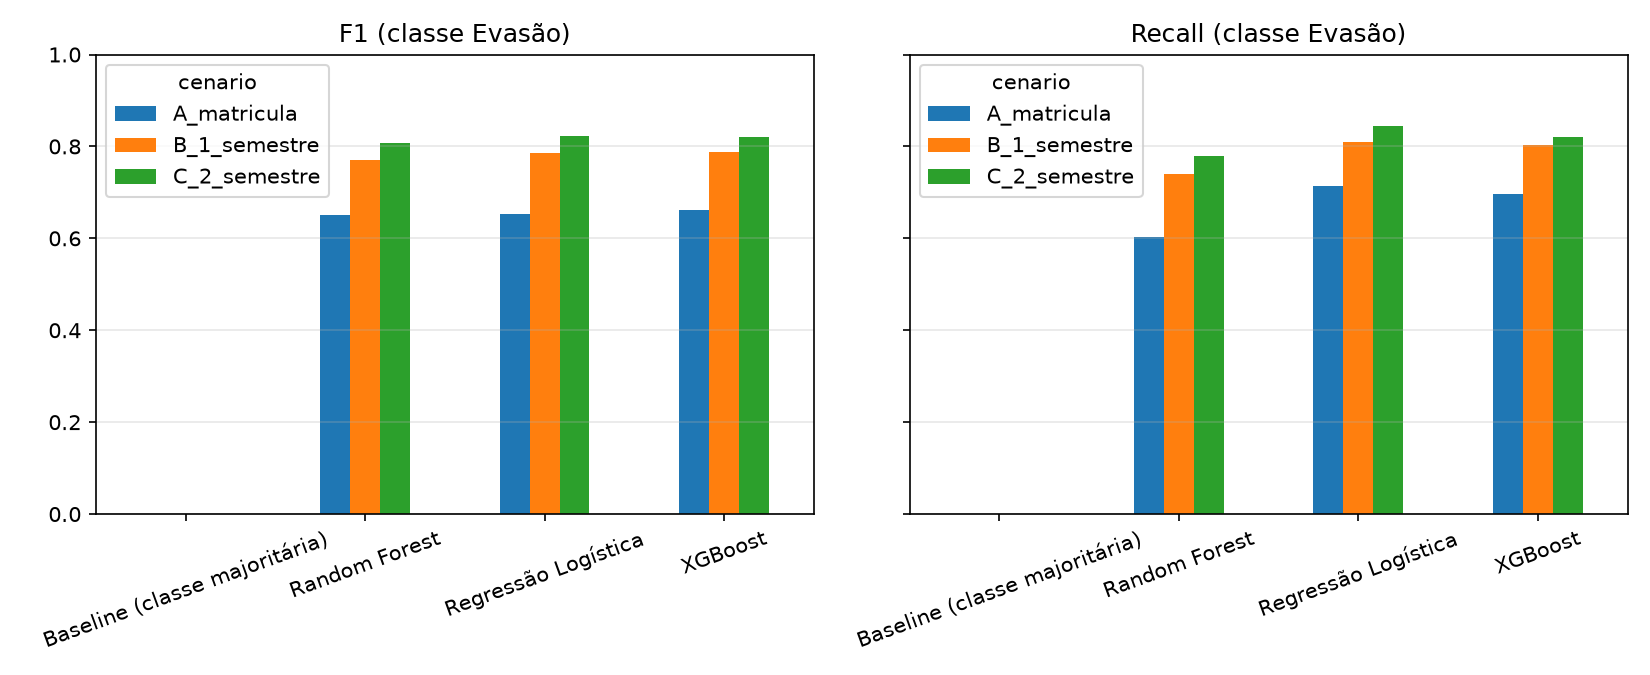

In [3]:
display(Image('../reports/figures/comparacao_modelos.png'))

## Explicabilidade (SHAP) - fim do 1? semestre

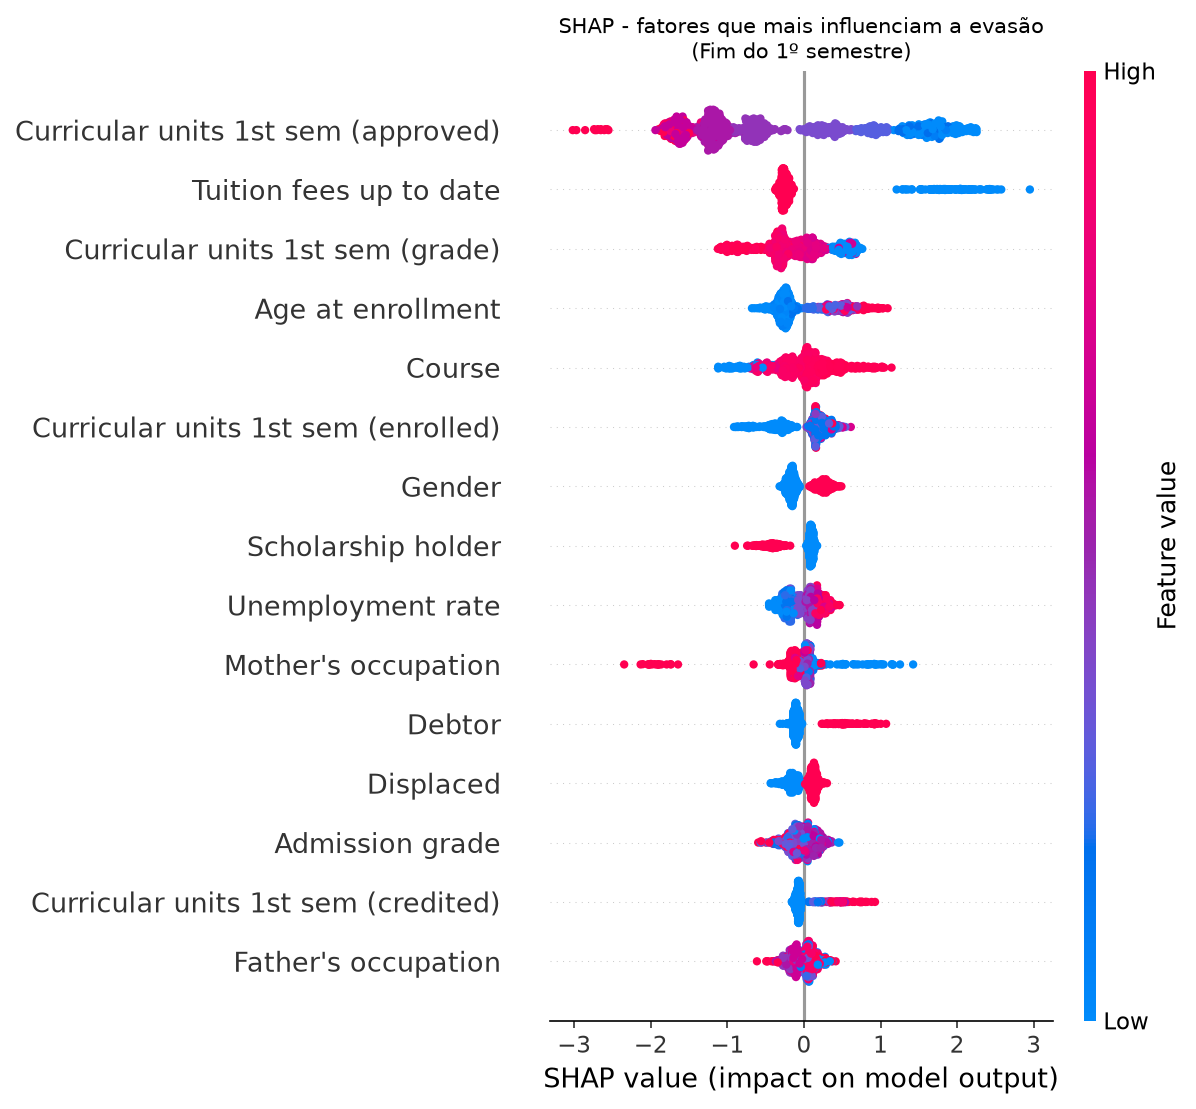

In [4]:
display(Image('../reports/figures/shap_summary_B_1_semestre.png', width=650))

## Auditoria de justi?a por grupo

In [5]:
pd.read_csv('../reports/justica_B_1_semestre.csv').round(3)

,cenario,atributo,grupo,n,taxa_real_evasao,taxa_de_alerta,recall,precisao,falso_positivo_rate
0,B_1_semestre,Gender,Feminino,564,0.245,0.392,0.870,0.543,0.237
1,B_1_semestre,Gender,Masculino,321,0.455,0.651,0.897,0.627,0.446
2,B_1_semestre,Scholarship holder,Não bolsista,654,0.390,0.580,0.918,0.617,0.363
3,B_1_semestre,Scholarship holder,Bolsista,231,0.126,0.221,0.586,0.333,0.168
4,B_1_semestre,Debtor,Não devedor,795,0.292,0.448,0.858,0.559,0.279
5,B_1_semestre,Debtor,Devedor,90,0.578,0.822,1.000,0.703,0.579


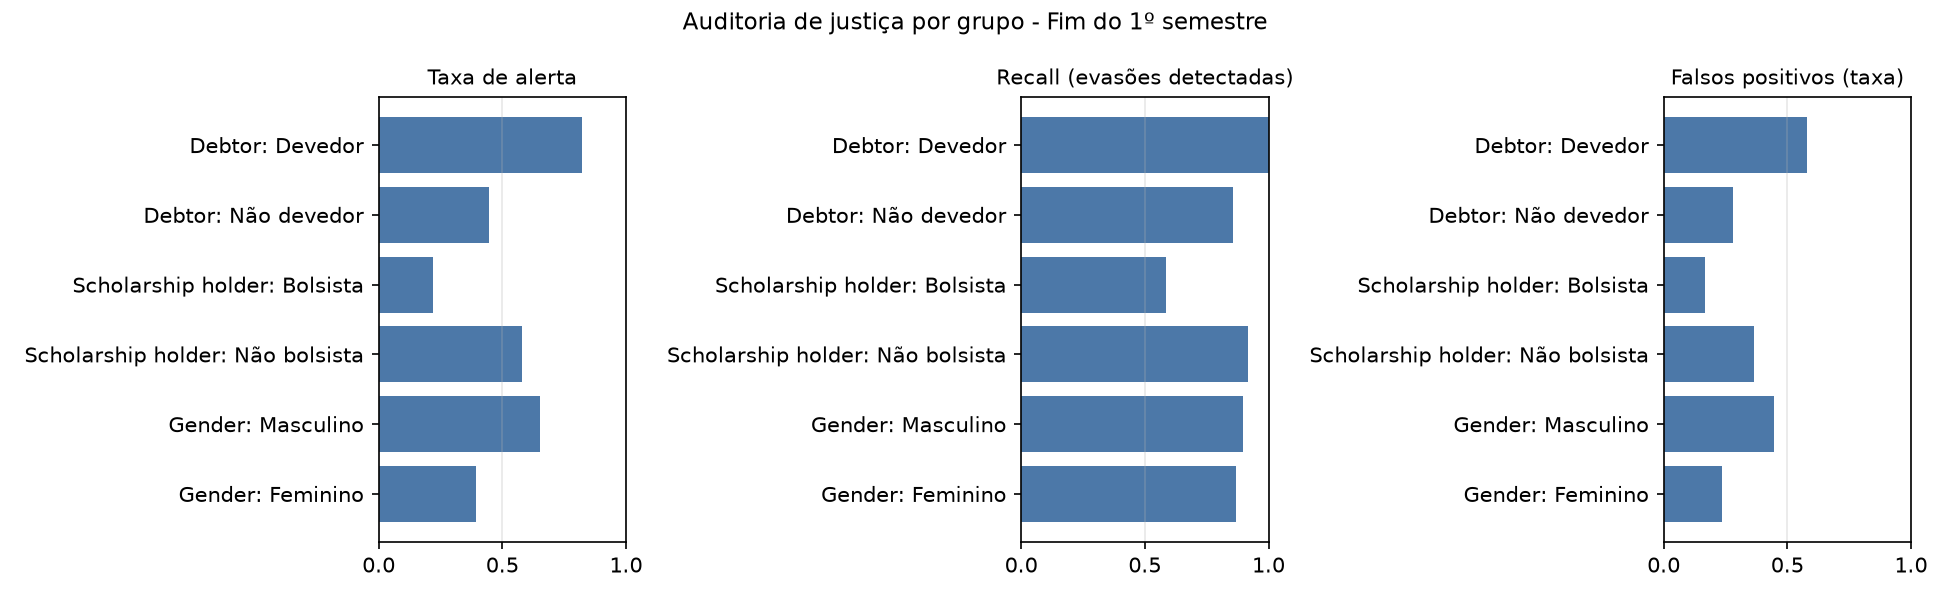

In [6]:
display(Image('../reports/figures/justica_B_1_semestre.png'))